# PraNet vs. PraNet + Dynamic Convolution


## STEP 1 - Get the PraNet code and check the GPU

In [1]:
import os, sys, subprocess, glob, re, time, hashlib

ROOT = '/kaggle/working/PraNet'

def sh(cmd, cwd=ROOT, quiet=False):
    # run a shell command and print what it says (quiet=True: print only if it failed)
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True, cwd=cwd)
    out = (r.stdout + r.stderr).strip()
    if out and (not quiet or r.returncode != 0):
        print(out)
    return r.returncode

if not os.path.isdir(ROOT):
    sh('git clone https://github.com/DengPingFan/PraNet', cwd='/kaggle/working')
assert os.path.isdir(ROOT), 'Could not get the PraNet code. Is Internet turned ON in Settings?'
sh('pip install -q thop')
os.chdir(ROOT)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
sh('nvidia-smi --query-gpu=name,memory.total --format=csv,noheader')
import torch
print('python', sys.version.split()[0], '| torch', torch.__version__, '| GPU available:', torch.cuda.is_available())
print('STEP 1 done. Code folder:', ROOT)

Cloning into 'PraNet'...
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
python 3.13.16 | torch 2.11.0+cu130 | GPU available: True
STEP 1 done. Code folder: /kaggle/working/PraNet


## STEP 2 - Download the data 

In [2]:
def md5(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

D = ROOT + '/data'
if os.path.isdir(D + '/TrainDataset/image') and os.path.isdir(D + '/TestDataset/Kvasir'):
    print('Data folders already exist - nothing to download. Go to STEP 3.')
else:
    os.chdir('/kaggle/working')
    zp = '/kaggle/working/PolypDataset.zip'
    if not os.path.exists('/kaggle/working/polyp_raw/NewTRimage'):
        get_ipython().system('wget -c --progress=dot:giga -O PolypDataset.zip "https://zenodo.org/records/5579392/files/PolypDataset.zip?download=1"')
        assert md5(zp) == '0c45c453bc16424df7a2528966ccd939', 'Download is incomplete or damaged - run this cell again'
        sh('unzip -q -o PolypDataset.zip "TestDataset/*" "NewTRimage/*" "NewTRmask/*" -d polyp_raw', cwd='/kaggle/working')
        os.remove(zp)
    sh('rm -rf data && mkdir -p data/TrainDataset')
    sh('cp -r /kaggle/working/polyp_raw/TestDataset/TestDataset data/TestDataset')
    sh('cp -r /kaggle/working/polyp_raw/NewTRimage data/TrainDataset/image')
    sh('cp -r /kaggle/working/polyp_raw/NewTRmask data/TrainDataset/masks')
    sh('ln -s image data/TrainDataset/images')      # PraNet looks for a folder called "images"
    os.chdir(ROOT)
    print('STEP 2 done.')

--2026-11-13 16:45:01--  https://zenodo.org/records/5579392/files/PolypDataset.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.42.113, 188.185.45.63, 188.185.47.192, ...
Connecting to zenodo.org (zenodo.org)|188.185.42.113|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4009054243 (3.7G) [application/octet-stream]
Saving to: ‘PolypDataset.zip’

     0K ........ ........ ........ ........  0% 2.58M 24m27s
 32768K ........ ........ ........ ........  1% 3.40M 21m20s
 65536K ........ ........ ........ ........  2% 3.60M 19m52s
 98304K ........ ........ ........ ........  3% 3.52M 19m9s
131072K ........ ........ ........ ........  4% 3.54M 18m38s
163840K ........ ........ ........ ........  5% 7.57M 16m44s
196608K ........ ........ ........ ........  5% 4.03M 16m20s
229376K ........ ........ ........ ........  6% 3.97M 16m2s
262144K ........ ........ ........ ........  7% 7.87M 14m58s
294912K ........ ........ ........ ........  8% 3.73M 14m54s
327680K

## STEP 3 - Check the data

In [3]:
stem = lambda f: os.path.splitext(f)[0]
ext = lambda f: os.path.splitext(f)[1].lower()
problems = []
imgs = os.listdir(D + '/TrainDataset/image'); msks = os.listdir(D + '/TrainDataset/masks')
print('training images:', len(imgs), '| masks:', len(msks))
if len(imgs) != 1450 or len(msks) != 1450: problems.append('training count is not 1450')
if {stem(f) for f in imgs} != {stem(f) for f in msks}: problems.append('image and mask names do not match')
if any(ext(f) != '.png' for f in msks): problems.append('some masks are not .png')
expected = {'Kvasir': 100, 'CVC-ClinicDB': 62, 'CVC-300': 60, 'CVC-ColonDB': 380, 'ETIS-LaribPolypDB': 196}
tr = {stem(f) for f in imgs}
for name, n in expected.items():
    te = os.listdir(f'{D}/TestDataset/{name}/images'); gt = os.listdir(f'{D}/TestDataset/{name}/masks')
    print(f'{name:18s} images={len(te):3d} masks={len(gt):3d} (expected {n})')
    if len(te) != n or len(gt) != n: problems.append(name + ': wrong count')
    if name in ('Kvasir', 'CVC-ClinicDB') and (tr & {stem(f) for f in te}):
        problems.append(name + ': test images also appear in training!')
print()
print('ALL CHECKS PASSED' if not problems else 'PROBLEMS: ' + '; '.join(problems))

training images: 1450 | masks: 1450
Kvasir             images=100 masks=100 (expected 100)
CVC-ClinicDB       images= 62 masks= 62 (expected 62)
CVC-300            images= 60 masks= 60 (expected 60)
CVC-ColonDB        images=380 masks=380 (expected 380)
ETIS-LaribPolypDB  images=196 masks=196 (expected 196)

ALL CHECKS PASSED


## STEP 4 - Get the backbone weights (Res2Net)

In [4]:
W = ROOT + '/pretrained/res2net50_v1b_26w_4s-3cf99910.pth'
def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

os.makedirs(ROOT + '/pretrained', exist_ok=True)
if not (os.path.exists(W) and sha256(W).startswith('3cf99910')):
    get_ipython().system('wget -q -O ' + W + ' "https://shanghuagao.oss-cn-beijing.aliyuncs.com/res2net/res2net50_v1b_26w_4s-3cf99910.pth"')
assert os.path.exists(W) and sha256(W).startswith('3cf99910'), 'Weights file is missing or wrong - run this cell again'
print('backbone weights OK')

backbone weights OK


## STEP 5 - Prepare the code 

In [5]:
import importlib

# ---------- 1. patch PraNet's own files (safe to run twice) ----------
p = ROOT + '/lib/Res2Net_v1b.py'
s = open(p).read()
old = '/media/nercms/NERCMS/GepengJi/Medical_Seqmentation/CRANet/models/res2net50_v1b_26w_4s-3cf99910.pth'
s = s.replace(old, W)
assert W in s, 'Could not find the weights path in lib/Res2Net_v1b.py'
open(p, 'w').write(s)

p = ROOT + '/MyTest.py'
s = open(p).read()
s = s.replace('from scipy import misc', 'import imageio')
s = s.replace('misc.imsave(save_path+name, res)', 'imageio.imwrite(save_path+name, (res*255).astype("uint8"))')
s = s.replace("'./results/PraNet/{}/'.format(_data_name)",
              "'./results/{}/{}/'.format(os.environ.get('PRED_TAG', 'PraNet'), _data_name)")

if "os.environ.get('DYN_K')" not in s:
    s = s.replace('    model = PraNet()\n',
                  "    model = PraNet()\n"
                  "    if os.environ.get('DYN_K'):\n"
                  "        from lib.dynamic_conv import convert_ra_to_dynamic\n"
                  "        model = convert_ra_to_dynamic(model, K=int(os.environ['DYN_K']))\n"
                  "        # Turn on attention recording\n"
                  "        for m in model.modules():\n"
                  "            if hasattr(m, 'K'):\n"
                  "                m.record_attention = True\n"
                  "                m.attention_weights = []\n")
    
    s = s.replace("print(_data_name, 'Finish!')",
                  "print(_data_name, 'Finish!')\n"
                  "    import numpy as np\n"
                  "    if os.environ.get('DYN_K'):\n"
                  "        weights = {name: np.concatenate(m.attention_weights, axis=0) for name, m in model.named_modules() if hasattr(m, 'K')}\n"
                  "        np.save(f'./results/{os.environ.get(\"PRED_TAG\", \"PraNet\")}/{_data_name}/attention_weights.npy', weights)\n")

open(p, 'w').write(s)

# ---------- 2. our own files ----------
DYN = r'''
import math, os
import torch
import torch.nn as nn
import torch.nn.functional as F


class DynamicConv2d(nn.Module):
    # K kernels are mixed per input image by a small attention network (global-pool -> MLP -> K weights)
    def __init__(self, in_ch, out_ch, kernel_size, stride=1, padding=0, dilation=1,
                 bias=False, K=4, reduction=4, temperature=1.0):
        super().__init__()
        ks = kernel_size if isinstance(kernel_size, tuple) else (kernel_size, kernel_size)
        self.in_ch, self.out_ch, self.ks = in_ch, out_ch, ks
        self.stride, self.padding, self.dilation = stride, padding, dilation
        self.K, self.temperature = K, temperature
        hidden = max(in_ch // reduction, 4)
        self.attn = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_ch, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, K, 1),
        )
        self.weight = nn.Parameter(torch.empty(K, out_ch, in_ch, ks[0], ks[1]))
        for k in range(K):
            nn.init.kaiming_uniform_(self.weight.data[k], a=math.sqrt(5))
        self.bias = nn.Parameter(torch.zeros(K, out_ch)) if bias else None

    def forward(self, x):
        B, C, H, W = x.shape
        a = F.softmax(self.attn(x).view(B, self.K) / self.temperature, dim=1)      # (B, K)
        
        # Add this block to save weights during testing
        if getattr(self, 'record_attention', False):
            self.attention_weights.append(a.detach().cpu().numpy())
            
        w = (a @ self.weight.view(self.K, -1)).view(B * self.out_ch, C, *self.ks)  # one kernel per image
        b = (a @ self.bias).view(-1) if self.bias is not None else None
        out = F.conv2d(x.reshape(1, B * C, H, W), w, b, self.stride, self.padding,
                       self.dilation, groups=B)
        return out.view(B, self.out_ch, out.shape[-2], out.shape[-1])


def convert_ra_to_dynamic(model, K=4, stages=None, temperature=1.0, kernel_sizes=((3, 3), (5, 5))):
    # Swap convs (in==out channels, kernel in kernel_sizes) inside ra<stage>_* for DynamicConv2d.
    # stages=None -> read the DYN_STAGES environment variable ("2,3" by default).
    if stages is None:
        stages = tuple(int(s) for s in os.environ.get('DYN_STAGES', '2,3').split(','))
    replaced = []
    for name, m in list(model.named_modules()):
        if not any(name.startswith('ra%d_' % s) for s in stages):
            continue
        for cname, child in list(m.named_children()):
            if (isinstance(child, nn.Conv2d) and tuple(child.kernel_size) in kernel_sizes
                    and child.in_channels == child.out_channels):
                setattr(m, cname, DynamicConv2d(
                    child.in_channels, child.out_channels, child.kernel_size, child.stride,
                    child.padding, child.dilation, bias=child.bias is not None, K=K,
                    temperature=temperature))
                replaced.append(name + '.' + cname)
    print('convert_ra_to_dynamic: stages=%s K=%d replaced %d layers' % (stages, K, len(replaced)), replaced)
    return model
'''

EVAL = r'''
import argparse, os, csv, numpy as np
from PIL import Image
p = argparse.ArgumentParser()
p.add_argument('--pred_root', default='results/PraNet')
p.add_argument('--gt_root', default='data/TestDataset')
p.add_argument('--tag', default='baseline')
p.add_argument('--seed', default='')
p.add_argument('--out', default='results/eval_summary.csv')
a = p.parse_args()
stem = lambda f: os.path.splitext(f)[0]
rows = []
for ds in ['Kvasir', 'CVC-ClinicDB', 'CVC-300', 'CVC-ColonDB', 'ETIS-LaribPolypDB']:
    pdir = f'{a.pred_root}/{ds}'; gdir = f'{a.gt_root}/{ds}/masks'
    if not os.path.isdir(pdir):
        continue
    preds = {stem(f): f for f in os.listdir(pdir)}
    dices, ious = [], []
    for g in sorted(os.listdir(gdir)):
        s = stem(g)
        if s not in preds:
            continue
        gt = np.array(Image.open(f'{gdir}/{g}').convert('L')) > 127
        pr = np.array(Image.open(f'{pdir}/{preds[s]}').convert('L').resize(gt.shape[::-1])) > 127
        inter = (gt & pr).sum(); union = (gt | pr).sum()
        dices.append((2 * inter + 1e-8) / (gt.sum() + pr.sum() + 1e-8))
        ious.append((inter + 1e-8) / (union + 1e-8))
    rows.append([a.tag, a.seed, ds, len(dices), round(float(np.mean(dices)), 4), round(float(np.mean(ious)), 4)])
    print(rows[-1])
os.makedirs(os.path.dirname(a.out), exist_ok=True)
new = not os.path.exists(a.out)
with open(a.out, 'a', newline='') as f:
    w = csv.writer(f)
    if new:
        w.writerow(['tag', 'seed', 'dataset', 'n_images', 'mean_dice', 'mean_iou'])
    w.writerows(rows)
'''
open(ROOT + '/lib/dynamic_conv.py', 'w').write(DYN.lstrip())
open(ROOT + '/evaluate.py', 'w').write(EVAL.lstrip())

def make_train_script(dst, dynamic=False, save_every_epoch=False):
    # copy of PraNet's MyTrain.py + seeding (SEED env var) + optional dynamic convolution
    s = open(ROOT + '/MyTrain.py').read()
    s = s.replace("reduce='none'", "reduction='none'")
    anchor = '# ---- build models ----'
    assert anchor in s, 'MyTrain.py looks different than expected - send line 95-105 to your assistant'
    seed_code = ("import random, numpy as np\n"
                 "    _s = int(os.environ.get('SEED', 0))\n"
                 "    random.seed(_s); np.random.seed(_s); torch.manual_seed(_s); torch.cuda.manual_seed_all(_s)\n"
                 "    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False\n"
                 "    ")
    s = s.replace(anchor, seed_code + anchor, 1)
    if dynamic:
        old = 'model = PraNet().cuda()'
        assert old in s, 'could not find the model line in MyTrain.py'
        s = s.replace(old, "from lib.dynamic_conv import convert_ra_to_dynamic\n"
                           "    model = convert_ra_to_dynamic(PraNet(), K=int(os.environ.get('DYN_K', 4))).cuda()", 1)
    if save_every_epoch:
        assert '(epoch+1) % 10 == 0' in s, 'save rule not found'
        s = s.replace('(epoch+1) % 10 == 0', 'True', 1)
    open(ROOT + '/' + dst, 'w').write(s)
    print('wrote', dst)

make_train_script('MyTrain_base_full.py')                           # real baseline run
make_train_script('MyTrain_dyn_full.py', dynamic=True)              # real dynamic run
make_train_script('MyTrain_dyn_quick.py', dynamic=True, save_every_epoch=True)   # 4-minute test of the dynamic model

# --- self-test of the dynamic layer (runs on CPU) ---
for m in [k for k in sys.modules if k == 'lib' or k.startswith('lib.')]:
    del sys.modules[m]
import torch.nn as nn
from lib.dynamic_conv import DynamicConv2d
dc = DynamicConv2d(16, 16, 3, padding=1, K=1)
sc = nn.Conv2d(16, 16, 3, padding=1, bias=False); sc.weight.data = dc.weight.data[0].clone()
x = torch.randn(2, 16, 9, 9)
assert torch.allclose(dc(x), sc(x), atol=1e-5), 'dynamic conv with K=1 should equal a normal conv'
y = DynamicConv2d(16, 16, 5, padding=2, K=4)(x); y.sum().backward()
print('dynamic conv self-test OK')

wrote MyTrain_base_full.py
wrote MyTrain_dyn_full.py
wrote MyTrain_dyn_quick.py
dynamic conv self-test OK


## STEP 6 - Start training the ORIGINAL model (seed 0) 

In [6]:
procs = {}
def launch(tag, script, seed, env='', gpu=0):
    cmd = f'CUDA_VISIBLE_DEVICES={gpu} SEED={seed} {env} python {script} --train_save {tag} > {tag}.log 2>&1'
    procs[tag] = subprocess.Popen(cmd, shell=True, cwd=ROOT)
    print('started', tag, '| progress is written to', tag + '.log')

launch('base_s0', 'MyTrain_base_full.py', seed=0,gpu=0)

started base_s0 | progress is written to base_s0.log


## STEP 7 - Check progress 

In [33]:
def progress(tag):
    if tag in procs:
        print(tag, '->', 'still running' if procs[tag].poll() is None else 'finished (exit code %s)' % procs[tag].poll())
    else:
        print(tag, '-> not started in this session (check the log below)')
    sh(f'tail -n 3 {tag}.log')

progress('base_s0')

base_s0 -> finished (exit code 0)
2026-11-13 18:09:36.854242 Epoch [019/020], Step [0080/0091], [lateral-2: 0.1208, lateral-3: 0.1392, lateral-4: 0.1797, lateral-5: 0.1291]
2026-11-13 18:10:01.828743 Epoch [019/020], Step [0091/0091], [lateral-2: 0.1189, lateral-3: 0.1370, lateral-4: 0.1772, lateral-5: 0.1278]
[Saving Snapshot:] snapshots/base_s0/PraNet-19.pth


## STEP 8 - Score the original model

In [ ]:
def last_ckpt(tag):
    files = glob.glob(f'{ROOT}/snapshots/{tag}/PraNet-*.pth')
    return max(files, key=lambda f: int(re.findall(r'PraNet-(\d+)\.pth', f)[0])) if files else None

def evaluate_run(tag, seed, label, env=''):
    if tag in procs and procs[tag].poll() is None:
        print('Still training - wait until STEP 7 says finished.'); return
    ck = last_ckpt(tag)
    if ck is None:
        print('No checkpoint found for', tag, '- did training finish? Look at', tag + '.log'); return
    print('Using checkpoint:', os.path.basename(ck))
    sh(f'{env} PRED_TAG={tag} python MyTest.py --pth_path {ck}', quiet=True)
    sh(f'python evaluate.py --pred_root results/{tag} --tag {label} --seed {seed}')

evaluate_run('base_s0', 0, 'baseline')

## STEP 9 - Start training the DYNAMIC model 

In [7]:
launch('dyn_s0', 'MyTrain_dyn_full.py', seed=0, env='DYN_K=4 DYN_STAGES=2,3',gpu=1)    # add gpu=1 to use the second GPU

started dyn_s0 | progress is written to dyn_s0.log


In [32]:
progress('dyn_s0')

dyn_s0 -> finished (exit code 0)
2026-11-13 18:13:30.634953 Epoch [019/020], Step [0080/0091], [lateral-2: 0.1097, lateral-3: 0.1284, lateral-4: 0.1716, lateral-5: 0.1199]
2026-11-13 18:13:57.174835 Epoch [019/020], Step [0091/0091], [lateral-2: 0.1126, lateral-3: 0.1302, lateral-4: 0.1726, lateral-5: 0.1218]
[Saving Snapshot:] snapshots/dyn_s0/PraNet-19.pth


In [50]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import os, sys, math, base64
import numpy as np
from PIL import Image
from IPython.display import HTML, display

# Ensure local PraNet modules are accessible
if '/kaggle/working/PraNet' not in sys.path:
    sys.path.insert(0, '/kaggle/working/PraNet')
from lib.PraNet_Res2Net import PraNet

# 1. Force a clean, in-memory definition of the dynamic layer with recording enabled
class StandaloneDynamicConv2d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, stride=1, padding=0, dilation=1,
                 bias=False, K=4, reduction=4, temperature=1.0):
        super().__init__()
        ks = kernel_size if isinstance(kernel_size, tuple) else (kernel_size, kernel_size)
        self.in_ch, self.out_ch, self.ks = in_ch, out_ch, ks
        self.stride, self.padding, self.dilation = stride, padding, dilation
        self.K, self.temperature = K, temperature
        hidden = max(in_ch // reduction, 4)
        self.attn = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_ch, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, K, 1),
        )
        self.weight = nn.Parameter(torch.empty(K, out_ch, in_ch, ks[0], ks[1]))
        for k in range(K):
            nn.init.kaiming_uniform_(self.weight.data[k], a=math.sqrt(5))
        self.bias = nn.Parameter(torch.zeros(K, out_ch)) if bias else None

    def forward(self, x):
        B, C, H, W = x.shape
        a = F.softmax(self.attn(x).view(B, self.K) / self.temperature, dim=1)
        
        # Unconditionally record weights if the array is initialized
        if hasattr(self, 'attention_weights'):
            self.attention_weights.append(a.detach().cpu().numpy())
            
        w = (a @ self.weight.view(self.K, -1)).view(B * self.out_ch, C, *self.ks)
        b = (a @ self.bias).view(-1) if self.bias is not None else None
        out = F.conv2d(x.reshape(1, B * C, H, W), w, b, self.stride, self.padding,
                       self.dilation, groups=B)
        return out.view(B, self.out_ch, out.shape[-2], out.shape[-1])

def inject_dynamic_layers(model, K=4, stages=(2,3), temperature=1.0, kernel_sizes=((3, 3), (5, 5))):
    replaced = []
    for name, m in list(model.named_modules()):
        if not any(name.startswith(f'ra{s}_') for s in stages): continue
        for cname, child in list(m.named_children()):
            if (isinstance(child, nn.Conv2d) and tuple(child.kernel_size) in kernel_sizes
                    and child.in_channels == child.out_channels):
                new_layer = StandaloneDynamicConv2d(
                    child.in_channels, child.out_channels, child.kernel_size, child.stride,
                    child.padding, child.dilation, bias=child.bias is not None, K=K,
                    temperature=temperature)
                new_layer.attention_weights = [] # Initialize recording array
                setattr(m, cname, new_layer)
                replaced.append(name + '.' + cname)
    return model

print("1. Loading Dynamic K=4 Model (In-Memory)...")
model = inject_dynamic_layers(PraNet(), K=4, stages=(2,3)).cuda()
model.load_state_dict(torch.load('/kaggle/working/PraNet/snapshots/dyn_s0/PraNet-19.pth'))
model.eval()

print("2. Processing Kvasir Test Set...")
img_dir = '/kaggle/working/PraNet/data/TestDataset/Kvasir/images/'
transform = transforms.Compose([
    transforms.Resize((352, 352)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

for img_name in sorted(os.listdir(img_dir)):
    if img_name.endswith('.png') or img_name.endswith('.jpg'):
        img = Image.open(os.path.join(img_dir, img_name)).convert('RGB')
        img_tensor = transform(img).unsqueeze(0).cuda()
        with torch.no_grad():
            _ = model(img_tensor)

print("3. Exporting Attention Weights...")
weights = {name: np.concatenate(m.attention_weights, axis=0) for name, m in model.named_modules() if hasattr(m, 'attention_weights')}

os.makedirs('/kaggle/working/npy_backup', exist_ok=True)
file_path = '/kaggle/working/npy_backup/dyn_s0_Kvasir_attention.npy'
np.save(file_path, weights)

print("4. Generating Download Link...")
with open(file_path, "rb") as f:
    bytes_data = f.read()
    b64 = base64.b64encode(bytes_data).decode()
    html = f'<br><a download="dyn_s0_Kvasir_attention.npy" href="data:application/octet-stream;base64,{b64}" target="_blank" style="padding: 10px; background-color: #2b7bba; color: white; border-radius: 5px; text-decoration: none; font-size: 16px;"><b>⬇️ Click Here to Download Kvasir Attention Weights (.npy)</b></a>'
    display(HTML(html))

1. Loading Dynamic K=4 Model (In-Memory)...
2. Processing Kvasir Test Set...
3. Exporting Attention Weights...
4. Generating Download Link...


## STEP 10 - Score the dynamic model

In [34]:
# ---- helper functions (no training starts here) ----
procs = {}

def launch(tag, script, seed, env='', gpu=0):
    cmd = f'CUDA_VISIBLE_DEVICES={gpu} SEED={seed} {env} python {script} --train_save {tag} > {tag}.log 2>&1'
    procs[tag] = subprocess.Popen(cmd, shell=True, cwd=ROOT)
    print('started', tag, '| progress is written to', tag + '.log')

def progress(tag):
    if tag in procs:
        print(tag, '->', 'still running' if procs[tag].poll() is None else 'finished (exit code %s)' % procs[tag].poll())
    else:
        print(tag, '-> not started in this session (check the log below)')
    sh(f'tail -n 3 {tag}.log')

def evaluate_run(tag, seed, label, env=''):
    ck = f'{ROOT}/snapshots/{tag}/PraNet-19.pth'          # the FINAL checkpoint (epochs 9 and 19 are saved)
    if tag in procs and procs[tag].poll() is None:
        print('Still training - wait until progress() says finished.'); return
    if not os.path.exists(ck):
        print('PraNet-19.pth not found for', tag, '- training has not finished. Look at', tag + '.log'); return
    print('Using checkpoint:', os.path.basename(ck))
    sh(f'{env} PRED_TAG={tag} python MyTest.py --pth_path {ck}', quiet=True)
    sh(f'python evaluate.py --pred_root results/{tag} --tag {label} --seed {seed}')

def backup():
    import shutil
    os.makedirs('/kaggle/working/backup', exist_ok=True)
    for f in glob.glob(f'{ROOT}/results/*.csv') + glob.glob(f'{ROOT}/*.log'):
        shutil.copy(f, '/kaggle/working/backup/')
    for c in glob.glob(f'{ROOT}/snapshots/*/PraNet-19.pth'):
        shutil.copy(c, '/kaggle/working/backup/' + c.split('/')[-2] + '_PraNet-19.pth')
    os.chdir('/kaggle/working')
    shutil.make_archive('pranet_backup', 'zip', 'backup')
    from IPython.display import FileLink, display
    display(FileLink('pranet_backup.zip'))
    os.chdir(ROOT)


In [35]:
evaluate_run('base_s0', 0, 'baseline')
evaluate_run('dyn_s0', 0, 'dynamic_K4', env='DYN_K=4 DYN_STAGES=2,3')
backup()

Using checkpoint: PraNet-19.pth
['baseline', '0', 'Kvasir', 100, 0.9022, 0.8499]
['baseline', '0', 'CVC-ClinicDB', 62, 0.9165, 0.8646]
['baseline', '0', 'CVC-300', 60, 0.9048, 0.834]
['baseline', '0', 'CVC-ColonDB', 380, 0.6976, 0.6244]
['baseline', '0', 'ETIS-LaribPolypDB', 196, 0.597, 0.539]
Using checkpoint: PraNet-19.pth
['dynamic_K4', '0', 'Kvasir', 100, 0.9006, 0.8485]
['dynamic_K4', '0', 'CVC-ClinicDB', 62, 0.9275, 0.8811]
['dynamic_K4', '0', 'CVC-300', 60, 0.8998, 0.832]
['dynamic_K4', '0', 'CVC-ColonDB', 380, 0.7252, 0.6565]
['dynamic_K4', '0', 'ETIS-LaribPolypDB', 196, 0.6919, 0.6304]


/kaggle/working/pranet_backup.zip

## Run seed 1

In [36]:
launch('base_s1', 'MyTrain_base_full.py', seed=1, gpu=0)

started base_s1 | progress is written to base_s1.log


In [57]:
progress('base_s1')

base_s1 -> still running
2026-11-13 19:21:37.535918 Epoch [018/020], Step [0060/0091], [lateral-2: 0.1147, lateral-3: 0.1343, lateral-4: 0.1767, lateral-5: 0.1243]
2026-11-13 19:22:24.017561 Epoch [018/020], Step [0080/0091], [lateral-2: 0.1160, lateral-3: 0.1347, lateral-4: 0.1785, lateral-5: 0.1250]
2026-11-13 19:22:48.887627 Epoch [018/020], Step [0091/0091], [lateral-2: 0.1174, lateral-3: 0.1356, lateral-4: 0.1778, lateral-5: 0.1263]


In [37]:
launch('dyn_s1', 'MyTrain_dyn_full.py', seed=1, env='DYN_K=4 DYN_STAGES=2,3', gpu=1)

started dyn_s1 | progress is written to dyn_s1.log


In [60]:
progress('dyn_s1')

dyn_s1 -> finished (exit code 0)
2026-11-13 19:28:58.812535 Epoch [019/020], Step [0080/0091], [lateral-2: 0.1083, lateral-3: 0.1264, lateral-4: 0.1700, lateral-5: 0.1178]
2026-11-13 19:29:25.365004 Epoch [019/020], Step [0091/0091], [lateral-2: 0.1084, lateral-3: 0.1267, lateral-4: 0.1683, lateral-5: 0.1180]
[Saving Snapshot:] snapshots/dyn_s1/PraNet-19.pth


In [61]:
evaluate_run('base_s1', 1, 'baseline')
evaluate_run('dyn_s1', 1, 'dynamic_K4', env='DYN_K=4 DYN_STAGES=2,3')
backup()

Using checkpoint: PraNet-19.pth
['baseline', '1', 'Kvasir', 100, 0.9119, 0.858]
['baseline', '1', 'CVC-ClinicDB', 62, 0.9184, 0.8705]
['baseline', '1', 'CVC-300', 60, 0.8858, 0.8115]
['baseline', '1', 'CVC-ColonDB', 380, 0.7005, 0.6295]
['baseline', '1', 'ETIS-LaribPolypDB', 196, 0.6782, 0.6062]
Using checkpoint: PraNet-19.pth
['dynamic_K4', '1', 'Kvasir', 100, 0.9065, 0.853]
['dynamic_K4', '1', 'CVC-ClinicDB', 62, 0.9247, 0.8708]
['dynamic_K4', '1', 'CVC-300', 60, 0.8761, 0.8007]
['dynamic_K4', '1', 'CVC-ColonDB', 380, 0.7099, 0.6375]
['dynamic_K4', '1', 'ETIS-LaribPolypDB', 196, 0.7149, 0.637]


/kaggle/working/pranet_backup.zip

## Run seed 2

In [62]:
launch('base_s2', 'MyTrain_base_full.py', seed=2, gpu=0)


started base_s2 | progress is written to base_s2.log


In [63]:
launch('dyn_s2', 'MyTrain_dyn_full.py', seed=2, env='DYN_K=4 DYN_STAGES=2,3', gpu=1)

started dyn_s2 | progress is written to dyn_s2.log


In [72]:
progress('base_s2')

base_s2 -> still running
2026-11-13 20:23:54.314513 Epoch [014/020], Step [0060/0091], [lateral-2: 0.1283, lateral-3: 0.1485, lateral-4: 0.1923, lateral-5: 0.1422]
2026-11-13 20:24:40.745145 Epoch [014/020], Step [0080/0091], [lateral-2: 0.1327, lateral-3: 0.1543, lateral-4: 0.1967, lateral-5: 0.1480]
2026-11-13 20:25:05.727531 Epoch [014/020], Step [0091/0091], [lateral-2: 0.1414, lateral-3: 0.1643, lateral-4: 0.2049, lateral-5: 0.1570]


In [74]:
progress('dyn_s2')

dyn_s2 -> still running
2026-11-13 20:41:41.718321 Epoch [018/020], Step [0060/0091], [lateral-2: 0.2195, lateral-3: 0.2530, lateral-4: 0.3006, lateral-5: 0.2403]
2026-11-13 20:42:30.937626 Epoch [018/020], Step [0080/0091], [lateral-2: 0.2073, lateral-3: 0.2392, lateral-4: 0.2916, lateral-5: 0.2315]
2026-11-13 20:42:57.430849 Epoch [018/020], Step [0091/0091], [lateral-2: 0.1818, lateral-3: 0.2096, lateral-4: 0.2588, lateral-5: 0.2033]


In [75]:
evaluate_run('base_s2', 2, 'baseline')
evaluate_run('dyn_s2', 2, 'dynamic_K4', env='DYN_K=4 DYN_STAGES=2,3')
backup()

Using checkpoint: PraNet-19.pth
['baseline', '2', 'Kvasir', 100, 0.8957, 0.8423]
['baseline', '2', 'CVC-ClinicDB', 62, 0.9187, 0.8719]
['baseline', '2', 'CVC-300', 60, 0.9111, 0.845]
['baseline', '2', 'CVC-ColonDB', 380, 0.7149, 0.6432]
['baseline', '2', 'ETIS-LaribPolypDB', 196, 0.6612, 0.5926]
Using checkpoint: PraNet-19.pth
['dynamic_K4', '2', 'Kvasir', 100, 0.8916, 0.8372]
['dynamic_K4', '2', 'CVC-ClinicDB', 62, 0.8875, 0.8428]
['dynamic_K4', '2', 'CVC-300', 60, 0.8763, 0.8067]
['dynamic_K4', '2', 'CVC-ColonDB', 380, 0.63, 0.5643]
['dynamic_K4', '2', 'ETIS-LaribPolypDB', 196, 0.5439, 0.4936]


/kaggle/working/pranet_backup.zip

In [76]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import os, sys, math, base64, shutil
import numpy as np
from PIL import Image
from IPython.display import HTML, display

# Ensure local PraNet modules are accessible
if '/kaggle/working/PraNet' not in sys.path:
    sys.path.insert(0, '/kaggle/working/PraNet')
from lib.PraNet_Res2Net import PraNet

# 1. Standalone Dynamic Layer with Recording
class StandaloneDynamicConv2d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, stride=1, padding=0, dilation=1,
                 bias=False, K=4, reduction=4, temperature=1.0):
        super().__init__()
        ks = kernel_size if isinstance(kernel_size, tuple) else (kernel_size, kernel_size)
        self.in_ch, self.out_ch, self.ks = in_ch, out_ch, ks
        self.stride, self.padding, self.dilation = stride, padding, dilation
        self.K, self.temperature = K, temperature
        hidden = max(in_ch // reduction, 4)
        self.attn = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_ch, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, K, 1),
        )
        self.weight = nn.Parameter(torch.empty(K, out_ch, in_ch, ks[0], ks[1]))
        for k in range(K):
            nn.init.kaiming_uniform_(self.weight.data[k], a=math.sqrt(5))
        self.bias = nn.Parameter(torch.zeros(K, out_ch)) if bias else None

    def forward(self, x):
        B, C, H, W = x.shape
        a = F.softmax(self.attn(x).view(B, self.K) / self.temperature, dim=1)
        
        if hasattr(self, 'attention_weights'):
            self.attention_weights.append(a.detach().cpu().numpy())
            
        w = (a @ self.weight.view(self.K, -1)).view(B * self.out_ch, C, *self.ks)
        b = (a @ self.bias).view(-1) if self.bias is not None else None
        out = F.conv2d(x.reshape(1, B * C, H, W), w, b, self.stride, self.padding,
                       self.dilation, groups=B)
        return out.view(B, self.out_ch, out.shape[-2], out.shape[-1])

def inject_dynamic_layers(model, K=4, stages=(2,3), temperature=1.0, kernel_sizes=((3, 3), (5, 5))):
    replaced = []
    for name, m in list(model.named_modules()):
        if not any(name.startswith(f'ra{s}_') for s in stages): continue
        for cname, child in list(m.named_children()):
            if (isinstance(child, nn.Conv2d) and tuple(child.kernel_size) in kernel_sizes
                    and child.in_channels == child.out_channels):
                new_layer = StandaloneDynamicConv2d(
                    child.in_channels, child.out_channels, child.kernel_size, child.stride,
                    child.padding, child.dilation, bias=child.bias is not None, K=K,
                    temperature=temperature)
                new_layer.attention_weights = []
                setattr(m, cname, new_layer)
                replaced.append(name + '.' + cname)
    return model

# 2. Setup Image Processing
transform = transforms.Compose([
    transforms.Resize((352, 352)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
img_dir = '/kaggle/working/PraNet/data/TestDataset/Kvasir/images/'
os.makedirs('/kaggle/working/npy_backup', exist_ok=True)

# 3. Process Seed 1 and Seed 2 Checkpoints
for seed in [1, 2]:
    tag = f'dyn_s{seed}'
    ckpt_path = f'/kaggle/working/PraNet/snapshots/{tag}/PraNet-19.pth'
    
    if not os.path.exists(ckpt_path):
        print(f"Skipping {tag}: Checkpoint not found. Did the training finish?")
        continue
        
    print(f"Processing Kvasir Test Set for {tag}...")
    model = inject_dynamic_layers(PraNet(), K=4, stages=(2,3)).cuda()
    model.load_state_dict(torch.load(ckpt_path))
    model.eval()
    
    for img_name in sorted(os.listdir(img_dir)):
        if img_name.endswith(('.png', '.jpg')):
            img = Image.open(os.path.join(img_dir, img_name)).convert('RGB')
            img_tensor = transform(img).unsqueeze(0).cuda()
            with torch.no_grad():
                _ = model(img_tensor)
                
    weights = {name: np.concatenate(m.attention_weights, axis=0) for name, m in model.named_modules() if hasattr(m, 'attention_weights')}
    file_path = f'/kaggle/working/npy_backup/{tag}_Kvasir_attention.npy'
    np.save(file_path, weights)
    print(f"Saved: {tag}_Kvasir_attention.npy")

# 4. Generate the Final Zip Download Link
zip_path = '/kaggle/working/all_attention_weights_backup.zip'
shutil.make_archive(zip_path.replace('.zip', ''), 'zip', '/kaggle/working/npy_backup')

with open(zip_path, "rb") as f:
    bytes_data = f.read()
    b64 = base64.b64encode(bytes_data).decode()
    html = f'<br><a download="all_attention_weights_backup.zip" href="data:application/zip;base64,{b64}" target="_blank" style="padding: 10px; background-color: #2b7bba; color: white; border-radius: 5px; text-decoration: none; font-size: 16px;"><b>⬇️ Click Here to Download All Attention Weights Zip</b></a>'
    display(HTML(html))

Processing Kvasir Test Set for dyn_s1...
Saved: dyn_s1_Kvasir_attention.npy
Processing Kvasir Test Set for dyn_s2...
Saved: dyn_s2_Kvasir_attention.npy


## STEP 11 - Compare the two (average Dice per test set)

In [77]:
import pandas as pd
df = pd.read_csv(ROOT + '/results/eval_summary.csv')
df = df[df.tag != 'smoke']
display(df.pivot_table(index='dataset', columns='tag', values='mean_dice', aggfunc='mean').round(4))
print('seeds per model:', df.groupby('tag')['seed'].nunique().to_dict())

tag,baseline,dynamic_K4
dataset,,
CVC-300,0.9006,0.8904
CVC-ClinicDB,0.9179,0.9189
CVC-ColonDB,0.7043,0.7031
ETIS-LaribPolypDB,0.6455,0.6669
Kvasir,0.9033,0.9000


seeds per model: {'baseline': 3, 'dynamic_K4': 3}


In [78]:
import pandas as pd
df = pd.read_csv('/kaggle/working/PraNet/results/eval_summary.csv')
main = df[df.tag.isin(['baseline', 'dynamic_K4'])]
order = ['Kvasir', 'CVC-ClinicDB', 'CVC-300', 'CVC-ColonDB', 'ETIS-LaribPolypDB']

g = main.groupby(['dataset', 'tag']).mean_dice.agg(['mean', 'std', 'count']).round(4)
print(g.loc[order])

p = main.pivot_table(index=['dataset', 'seed'], columns='tag', values='mean_dice')
p['dyn_minus_base'] = (p['dynamic_K4'] - p['baseline']).round(4)
print(p.round(4).loc[order])

rep = df[df.tag.str.startswith('baseline') & (df.seed == 0)]
print(rep.pivot_table(index='dataset', columns='tag', values='mean_dice').loc[order])

                                mean     std  count
dataset           tag                              
Kvasir            baseline    0.9033  0.0082      3
                  dynamic_K4  0.9000  0.0053      5
CVC-ClinicDB      baseline    0.9179  0.0012      3
                  dynamic_K4  0.9189  0.0176      5
CVC-300           baseline    0.9006  0.0132      3
                  dynamic_K4  0.8904  0.0129      5
CVC-ColonDB       baseline    0.7043  0.0093      3
                  dynamic_K4  0.7031  0.0414      5
ETIS-LaribPolypDB baseline    0.6455  0.0428      3
                  dynamic_K4  0.6669  0.0695      5
tag                     baseline  dynamic_K4  dyn_minus_base
dataset           seed                                      
Kvasir            0       0.9022      0.9006         -0.0016
                  1       0.9119      0.9065         -0.0054
                  2       0.8957      0.8916         -0.0041
CVC-ClinicDB      0       0.9165      0.9275          0.0110
          

### Model size and speed 

In [79]:
import copy
from thop import profile
for m in [k for k in sys.modules if k == 'lib' or k.startswith('lib.')]:
    del sys.modules[m]
from lib.PraNet_Res2Net import PraNet
from lib.dynamic_conv import DynamicConv2d, convert_ra_to_dynamic

def dyn_ops(m, x, y):
    # thop does not know our layer, so count it by hand: the convolution + mixing the K kernels + the small attention net
    B, O, H, W = y.shape
    k = m.ks[0] * m.ks[1]
    hidden = m.attn[1].out_channels
    macs = B * (O * H * W * m.in_ch * k + m.K * O * m.in_ch * k + m.in_ch * hidden + hidden * m.K)
    m.total_ops += torch.DoubleTensor([int(macs)])

def measure(model, name):
    x = torch.randn(1, 3, 352, 352).cuda()
    n_params = sum(p.numel() for p in model.parameters())
    macs, _ = profile(copy.deepcopy(model).cuda().eval(), inputs=(x,), custom_ops={DynamicConv2d: dyn_ops}, verbose=False)
    net = copy.deepcopy(model).cuda().eval()
    with torch.no_grad():
        for _ in range(10): net(x)
        torch.cuda.synchronize(); t = time.time()
        for _ in range(50): net(x)
        torch.cuda.synchronize(); ms = (time.time() - t) / 50 * 1000
    print(f'{name:28s} params={n_params:,}  GMACs={macs/1e9:.4f}  latency={ms:.4f} ms')

measure(PraNet(), 'baseline')
measure(convert_ra_to_dynamic(PraNet(), K=4, stages=(2, 3)), 'dynamic K=4 stages 2,3')

baseline                     params=32,547,319  GMACs=13.1496  latency=20.4743 ms
dynamic K=4 stages 2,3       params=32,994,055  GMACs=13.1502  latency=21.9535 ms


### Are test images copies of training images? .

Kvasir             n=100 | similarity to closest training image: mean=0.77 max=0.92 | >0.9:   2  >0.7:  89
CVC-ClinicDB       n= 62 | similarity to closest training image: mean=0.93 max=1.00 | >0.9:  49  >0.7:  61
CVC-300            n= 60 | similarity to closest training image: mean=0.72 max=0.83 | >0.9:   0  >0.7:  44
CVC-ColonDB        n=380 | similarity to closest training image: mean=0.74 max=0.93 | >0.9:   8  >0.7: 264
ETIS-LaribPolypDB  n=196 | similarity to closest training image: mean=0.81 max=0.88 | >0.9:   0  >0.7: 190


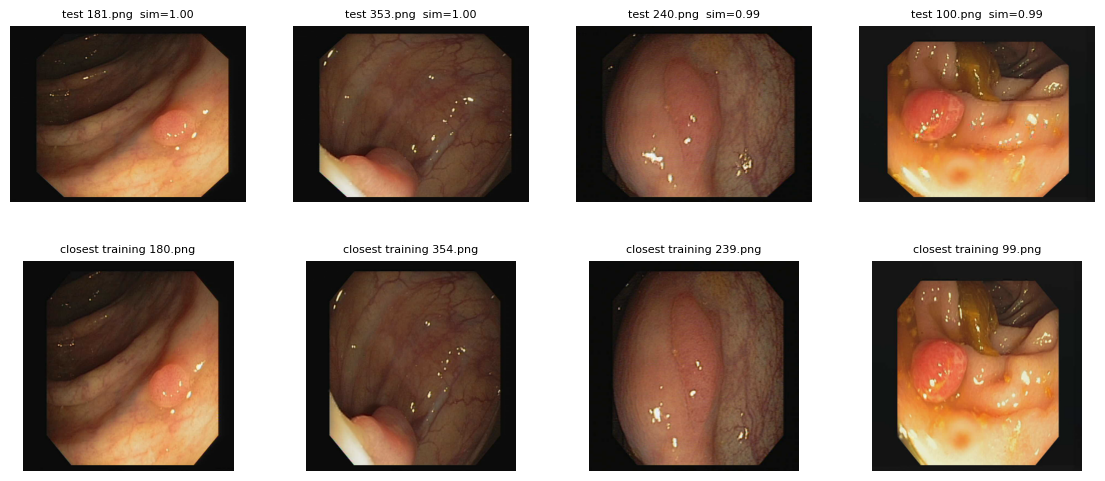

In [80]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def thumb(path, n=32):
    return np.asarray(Image.open(path).convert('L').resize((n, n), Image.BILINEAR), dtype=np.float32).ravel()

tr_dir = D + '/TrainDataset/image'
tr_names = sorted(os.listdir(tr_dir))
T = np.stack([thumb(f'{tr_dir}/{f}') for f in tr_names])
mu = T.mean(0)
def norm(A):
    A = A - mu
    return A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-8)
Tn = norm(T)
best_pairs = {}
for ds in ['Kvasir', 'CVC-ClinicDB', 'CVC-300', 'CVC-ColonDB', 'ETIS-LaribPolypDB']:
    d = f'{D}/TestDataset/{ds}/images'
    names = sorted(os.listdir(d))
    X = norm(np.stack([thumb(f'{d}/{f}') for f in names]))
    sim = X @ Tn.T
    j, best = sim.argmax(1), sim.max(1)
    best_pairs[ds] = (names, j, best)
    print(f'{ds:18s} n={len(names):3d} | similarity to closest training image: mean={best.mean():.2f} max={best.max():.2f} | >0.9: {(best > 0.9).sum():3d}  >0.7: {(best > 0.7).sum():3d}')

names, j, best = best_pairs['CVC-ClinicDB']
fig, ax = plt.subplots(2, 4, figsize=(14, 6))
for c, i in enumerate(np.argsort(-best)[:4]):
    ax[0, c].imshow(Image.open(f'{D}/TestDataset/CVC-ClinicDB/images/{names[i]}')); ax[0, c].set_title(f'test {names[i]}  sim={best[i]:.2f}', fontsize=8)
    ax[1, c].imshow(Image.open(f'{tr_dir}/{tr_names[j[i]]}')); ax[1, c].set_title(f'closest training {tr_names[j[i]]}', fontsize=8)
    ax[0, c].axis('off'); ax[1, c].axis('off')
plt.show()

## Sanity Checks

In [81]:
import os, numpy as np, pandas as pd
from PIL import Image

ROOT = '/kaggle/working/PraNet'
DS = ['Kvasir', 'CVC-ClinicDB', 'CVC-300', 'CVC-ColonDB', 'ETIS-LaribPolypDB']
PAIRS = {0: ('base_s0', 'dyn_s0'), 1: ('base_s1', 'dyn_s1'), 2: ('base_s2', 'dyn_s2')}
csv = pd.read_csv(f'{ROOT}/results/eval_summary.csv')

def load(p, size=None):
    im = Image.open(p).convert('L')
    if size is not None and im.size != size:
        im = im.resize(size, Image.BILINEAR)
    return np.asarray(im, dtype=np.float32) / 255.

def dice_per_image(run, ds):
    pdir = f'{ROOT}/results/{run}/{ds}'
    gdir = f'{ROOT}/data/TestDataset/{ds}/masks'
    if not os.path.isdir(pdir): return None
    preds = {os.path.splitext(f)[0]: f for f in os.listdir(pdir)}
    out = []
    for g in sorted(os.listdir(gdir)):
        s = os.path.splitext(g)[0]
        if s not in preds: return None          # names do not match: stop, tell me
        gt = Image.open(f'{gdir}/{g}').convert('L')
        gtm = np.asarray(gt, dtype=np.float32) / 255. > 0.5
        pm = load(f'{pdir}/{preds[s]}', gt.size) > 0.5
        inter = (gtm & pm).sum()
        out.append((2 * inter + 1e-8) / (gtm.sum() + pm.sum() + 1e-8))
    return np.array(out)

D = {}
for seed, (b, d) in PAIRS.items():
    for ds in DS:
        for run in (b, d):
            D[(run, ds)] = dice_per_image(run, ds)

# SANITY CHECK: my per-image mean must match eval_summary.csv
print('--- sanity check (mine vs csv), should agree to ~0.001 ---')
for seed, (b, d) in PAIRS.items():
    for tag, run in (('baseline', b), ('dynamic_K4', d)):
        for ds in DS:
            a = D[(run, ds)]
            row = csv[(csv.tag == tag) & (csv.seed == seed) & (csv.dataset == ds)]
            if a is None or row.empty:
                print(run, ds, 'MISSING'); continue
            print(run, ds, round(a.mean(), 4), 'csv', row.mean_dice.iloc[0])

rng = np.random.default_rng(0)
def boot(d, n=5000):
    idx = rng.integers(0, len(d), (n, len(d)))
    m = d[idx].mean(1)
    return d.mean(), np.percentile(m, 2.5), np.percentile(m, 97.5)

print('\n--- dyn minus base, per seed, 95% bootstrap CI over images ---')
for ds in DS:
    for seed, (b, d) in PAIRS.items():
        if D[(b, ds)] is None or D[(d, ds)] is None: continue
        m, lo, hi = boot(D[(d, ds)] - D[(b, ds)])
        print(f'{ds:18s} seed {seed}: {m:+.4f}  [{lo:+.4f}, {hi:+.4f}]')

print('\n--- dyn minus base, averaged over seeds per image ---')
for ds in DS:
    bs = [D[(b, ds)] for b, d in PAIRS.values() if D[(b, ds)] is not None]
    dy = [D[(d, ds)] for b, d in PAIRS.values() if D[(d, ds)] is not None]
    if not bs or not dy: continue
    m, lo, hi = boot(np.mean(dy, 0) - np.mean(bs, 0))
    print(f'{ds:18s} {m:+.4f}  [{lo:+.4f}, {hi:+.4f}]')

--- sanity check (mine vs csv), should agree to ~0.001 ---
base_s0 Kvasir 0.9022 csv 0.9022
base_s0 CVC-ClinicDB 0.9165 csv 0.9165
base_s0 CVC-300 0.9048 csv 0.9048
base_s0 CVC-ColonDB 0.6976 csv 0.6976
base_s0 ETIS-LaribPolypDB 0.597 csv 0.597
dyn_s0 Kvasir 0.9006 csv 0.9006
dyn_s0 CVC-ClinicDB 0.9275 csv 0.9275
dyn_s0 CVC-300 0.8998 csv 0.8998
dyn_s0 CVC-ColonDB 0.7252 csv 0.7252
dyn_s0 ETIS-LaribPolypDB 0.6919 csv 0.6919
base_s1 Kvasir 0.9119 csv 0.9119
base_s1 CVC-ClinicDB 0.9184 csv 0.9184
base_s1 CVC-300 0.8858 csv 0.8858
base_s1 CVC-ColonDB 0.7005 csv 0.7005
base_s1 ETIS-LaribPolypDB 0.6782 csv 0.6782
dyn_s1 Kvasir 0.9065 csv 0.9065
dyn_s1 CVC-ClinicDB 0.9247 csv 0.9247
dyn_s1 CVC-300 0.8761 csv 0.8761
dyn_s1 CVC-ColonDB 0.7099 csv 0.7099
dyn_s1 ETIS-LaribPolypDB 0.7149 csv 0.7149
base_s2 Kvasir 0.8957 csv 0.8957
base_s2 CVC-ClinicDB 0.9187 csv 0.9187
base_s2 CVC-300 0.9111 csv 0.9111
base_s2 CVC-ColonDB 0.7149 csv 0.7149
base_s2 ETIS-LaribPolypDB 0.6612 csv 0.6612
dyn_s2 Kvasir

## Report Output Generation

In [82]:
import os
import numpy as np
import pandas as pd
from PIL import Image

# --- Configuration ---
GT_ROOT = '/kaggle/working/PraNet/data/TestDataset'
PRED_ROOT = '/kaggle/working/PraNet/results'
DATASETS = ['Kvasir', 'CVC-ClinicDB', 'CVC-300', 'CVC-ColonDB', 'ETIS-LaribPolypDB']
MODELS = ['base_s0', 'dyn_s0', 'base_s1', 'dyn_s1', 'base_s2', 'dyn_s2']

print("Extracting per-image metrics...")
results_list = []

for ds in DATASETS:
    gdir = f'{GT_ROOT}/{ds}/masks'
    if not os.path.isdir(gdir): 
        continue
        
    for g_name in sorted(os.listdir(gdir)):
        stem = os.path.splitext(g_name)[0]
        gt = np.array(Image.open(f'{gdir}/{g_name}').convert('L')) > 127
        
        # 1. Polyp Size Categorization (EDA & Error Analysis)
        gt_sum = gt.sum()
        total_pixels = gt.size
        size_pct = (gt_sum / total_pixels) * 100
        
        if size_pct < 5: 
            size_cat = 'Small (<5%)'
        elif size_pct < 15: 
            size_cat = 'Medium (5-15%)'
        else: 
            size_cat = 'Large (>15%)'
            
        for model in MODELS:
            pdir = f'{PRED_ROOT}/{model}/{ds}'
            p_path = f'{pdir}/{stem}.png' 
            
            if not os.path.exists(p_path): 
                continue
                
            pr = np.array(Image.open(p_path).convert('L').resize(gt.shape[::-1])) > 127
            
            # 2. Recall and Precision Calculation
            TP = (gt & pr).sum()
            FP = pr.sum() - TP
            FN = gt_sum - TP
            
            dice = (2 * TP + 1e-8) / (gt_sum + pr.sum() + 1e-8)
            iou = (TP + 1e-8) / ((gt | pr).sum() + 1e-8)
            recall = (TP + 1e-8) / (gt_sum + 1e-8)
            precision = (TP + 1e-8) / (pr.sum() + 1e-8)
            
            tag = 'baseline' if 'base' in model else 'dynamic_K4'
            seed = int(model[-1])
            
            results_list.append({
                'dataset': ds,
                'image': stem,
                'size_pct': size_pct,
                'size_cat': size_cat,
                'tag': tag,
                'seed': seed,
                'dice': float(dice),
                'iou': float(iou),
                'recall': float(recall),
                'precision': float(precision)
            })

df_img = pd.DataFrame(results_list)
df_img.to_csv(f'{PRED_ROOT}/detailed_image_metrics.csv', index=False)
print("Saved detailed metrics to detailed_image_metrics.csv\n")

# --- Report Output Generation ---

# A. Recall & Precision Comparison (Section 4.1 & 4.5)
print("--- Mean Recall & Precision (Averaged across 3 seeds) ---")
agg_metrics = df_img.groupby(['dataset', 'tag'])[['recall', 'precision']].mean().round(4)
print(agg_metrics)
print("\n")

# B. Error Analysis by Polyp Size (Figure 4.4)
print("--- Mean Dice by Polyp Size (Averaged across 3 seeds) ---")
size_metrics = df_img.groupby(['dataset', 'size_cat', 'tag'])['dice'].mean().round(4).unstack()
size_metrics['dyn_minus_base'] = size_metrics['dynamic_K4'] - size_metrics['baseline']
print(size_metrics)
print("\n")

# 3. Bootstrap 95% Confidence Intervals (Table 4.4)
print("--- Table 4.4: Per-image paired comparison (Dynamic - Baseline Dice) ---")
print("Calculating 10,000-iteration bootstrap intervals per dataset (Seed 0 only for paired image-level comparison)...")

df_seed0 = df_img[df_img['seed'] == 0]
np.random.seed(42) # For reproducible bootstrapping

for ds in DATASETS:
    df_ds = df_seed0[df_seed0['dataset'] == ds]
    if df_ds.empty: continue
    
    # Pivot to align baseline and dynamic predictions for the exact same image
    pivot = df_ds.pivot(index='image', columns='tag', values='dice')
    diffs = (pivot['dynamic_K4'] - pivot['baseline']).values
    
    n_images = len(diffs)
    boot_means = []
    
    # Resample with replacement 10,000 times
    for _ in range(10000):
        sample = np.random.choice(diffs, size=n_images, replace=True)
        boot_means.append(np.mean(sample))
        
    lower_bound = np.percentile(boot_means, 2.5)
    upper_bound = np.percentile(boot_means, 97.5)
    mean_diff = np.mean(diffs)
    
    print(f"{ds:18s} | Diff: {mean_diff:+.4f} | 95% CI: [{lower_bound:+.4f}, {upper_bound:+.4f}]")

Extracting per-image metrics...
Saved detailed metrics to detailed_image_metrics.csv

--- Mean Recall & Precision (Averaged across 3 seeds) ---
                              recall  precision
dataset           tag                          
CVC-300           baseline    0.9503     0.8695
                  dynamic_K4  0.9381     0.8585
CVC-ClinicDB      baseline    0.9280     0.9167
                  dynamic_K4  0.9226     0.9115
CVC-ColonDB       baseline    0.7075     0.7867
                  dynamic_K4  0.6906     0.7743
ETIS-LaribPolypDB baseline    0.6737     0.6844
                  dynamic_K4  0.6814     0.6985
Kvasir            baseline    0.9069     0.9222
                  dynamic_K4  0.9076     0.9193


--- Mean Dice by Polyp Size (Averaged across 3 seeds) ---
tag                               baseline  dynamic_K4  dyn_minus_base
dataset           size_cat                                            
CVC-300           Large (>15%)      0.9646      0.9087         -0.0559
       

## Visualization

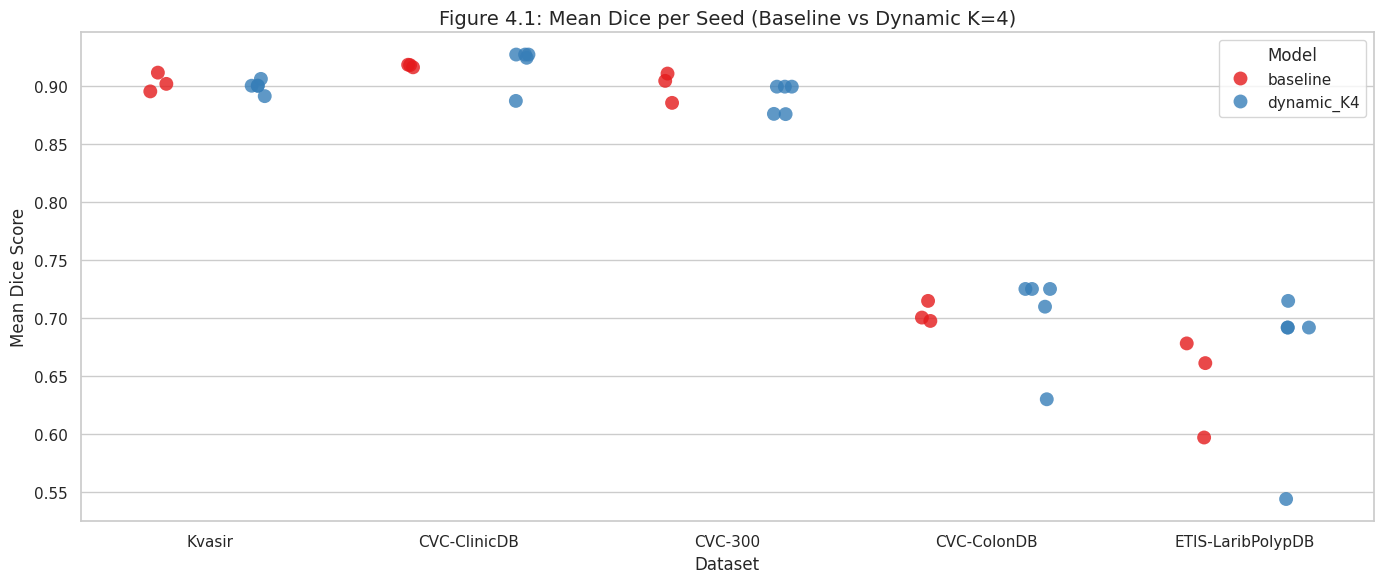

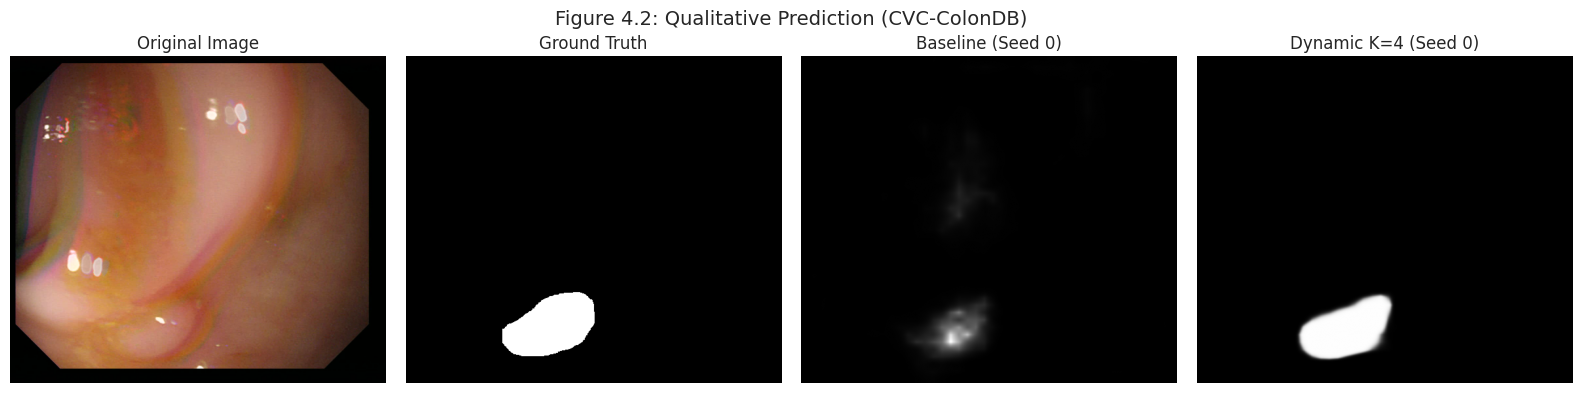

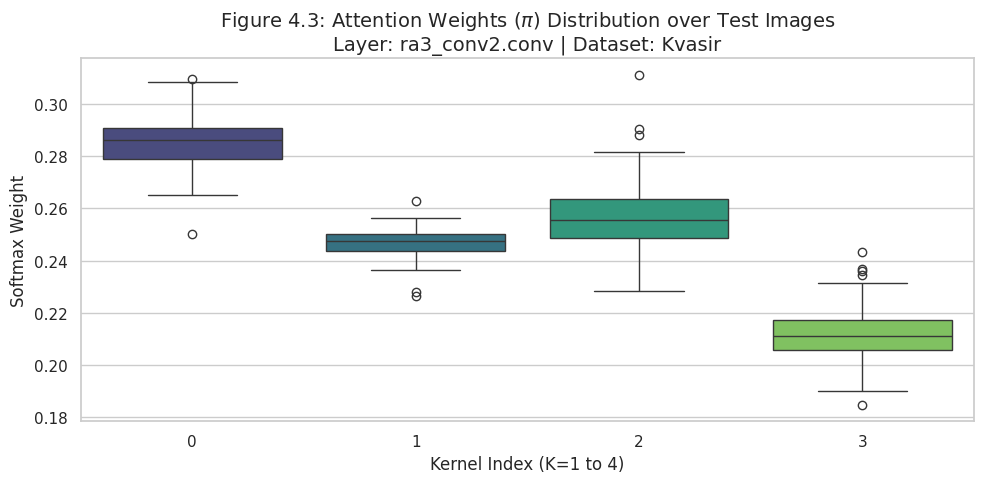

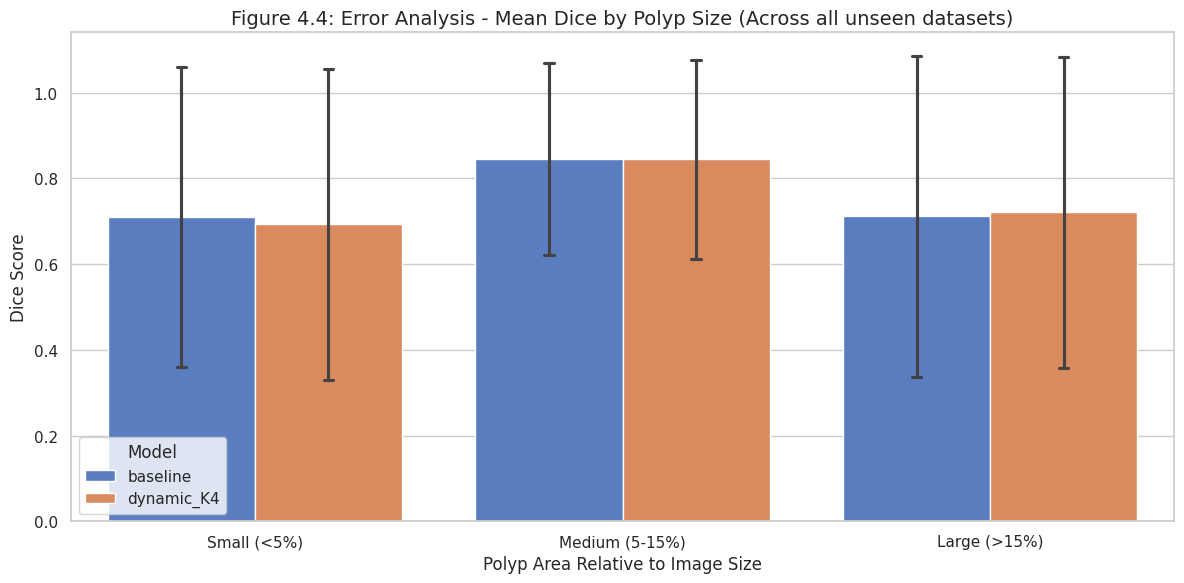

In [85]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# --- Configuration ---
ROOT = '/kaggle/working/PraNet'
RESULTS_DIR = f'{ROOT}/results'
DATASETS = ['Kvasir', 'CVC-ClinicDB', 'CVC-300', 'CVC-ColonDB', 'ETIS-LaribPolypDB']

# Load metrics generated from the previous script
df_img = pd.read_csv(f'{RESULTS_DIR}/detailed_image_metrics.csv')
df_summary = pd.read_csv(f'{RESULTS_DIR}/eval_summary.csv')

# Filter for the main comparison
df_main = df_summary[df_summary['tag'].isin(['baseline', 'dynamic_K4'])]

sns.set_theme(style="whitegrid")

# ==========================================
# Figure 4.1: Dice per seed (baseline vs dynamic)
# ==========================================
plt.figure(figsize=(14, 6))
sns.stripplot(
    data=df_main, x='dataset', y='mean_dice', hue='tag',
    dodge=True, marker='o', alpha=0.8, s=10, palette='Set1'
)
plt.title('Figure 4.1: Mean Dice per Seed (Baseline vs Dynamic K=4)', fontsize=14)
plt.ylabel('Mean Dice Score')
plt.xlabel('Dataset')
plt.legend(title='Model')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/Figure_4_1_Dice_Per_Seed.png', dpi=300)
plt.show()

# ==========================================
# Figure 4.2: Qualitative Predictions
# ==========================================
# Select one challenging dataset and image for visualization
sample_ds = 'CVC-ColonDB'
sample_img = '4' # Update this to a specific image stem you want to showcase

img_path = f'{ROOT}/data/TestDataset/{sample_ds}/images/{sample_img}.png'
gt_path = f'{ROOT}/data/TestDataset/{sample_ds}/masks/{sample_img}.png'
base_path = f'{RESULTS_DIR}/base_s0/{sample_ds}/{sample_img}.png'
dyn_path = f'{RESULTS_DIR}/dyn_s0/{sample_ds}/{sample_img}.png'

if os.path.exists(img_path) and os.path.exists(base_path):
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    
    axes[0].imshow(Image.open(img_path))
    axes[0].set_title('Original Image')
    
    axes[1].imshow(Image.open(gt_path).convert('L'), cmap='gray')
    axes[1].set_title('Ground Truth')
    
    axes[2].imshow(Image.open(base_path).convert('L'), cmap='gray')
    axes[2].set_title('Baseline (Seed 0)')
    
    axes[3].imshow(Image.open(dyn_path).convert('L'), cmap='gray')
    axes[3].set_title('Dynamic K=4 (Seed 0)')
    
    for ax in axes:
        ax.axis('off')
        
    plt.suptitle(f'Figure 4.2: Qualitative Prediction ({sample_ds})', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/Figure_4_2_Qualitative.png', dpi=300)
    plt.show()

# ==========================================
# Figure 4.3: Attention Weights (pi) Distribution
# ==========================================
# Updated to point to the standalone extraction folder
attn_path = '/kaggle/working/npy_backup/dyn_s0_Kvasir_attention.npy'

if os.path.exists(attn_path):
    weights_dict = np.load(attn_path, allow_pickle=True).item()
    
    # Extract weights for one of the dynamic layers (e.g., ra3_conv2)
    layer_name = list(weights_dict.keys())[0]
    W = weights_dict[layer_name] # Shape: (N_images, K)
    
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=W, palette='viridis')
    plt.title(fr'Figure 4.3: Attention Weights ($\pi$) Distribution over Test Images' + '\n' + f'Layer: {layer_name} | Dataset: Kvasir', fontsize=14)
    plt.xlabel('Kernel Index (K=1 to 4)')
    plt.ylabel('Softmax Weight')
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/Figure_4_3_Attention_Weights.png', dpi=300)
    plt.show()
else:
    print(f"ERROR: Could not find attention weights at {attn_path}")

# ==========================================
# Figure 4.4: Error Analysis by Polyp Size
# ==========================================
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_img, x='size_cat', y='dice', hue='tag',
    errorbar='sd', palette='muted', capsize=.05,
    order=['Small (<5%)', 'Medium (5-15%)', 'Large (>15%)']
)
plt.title('Figure 4.4: Error Analysis - Mean Dice by Polyp Size (Across all unseen datasets)', fontsize=14)
plt.ylabel('Dice Score')
plt.xlabel('Polyp Area Relative to Image Size')
plt.legend(title='Model')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/Figure_4_4_Error_By_Size.png', dpi=300)
plt.show()